In [1]:
%pip install scikit-learn
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers,datasets
from sklearn.model_selection import train_test_split
import random
import pandas as pd
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

**PART-A**

In [3]:
import tarfile
import pickle
import numpy as np

x_all, y_all = [], []

with tarfile.open("cifar-10-python.tar.gz", "r:gz") as tar:
    for i in range(1, 6):
        with tar.extractfile(
            f"cifar-10-batches-py/data_batch_{i}"
        ) as f:
            batch = pickle.load(f, encoding="bytes")
            x_all.append(batch[b"data"])
            y_all.extend(batch[b"labels"])

    with tar.extractfile("cifar-10-batches-py/test_batch") as f:
        batch = pickle.load(f, encoding="bytes")
        x_clean = batch[b"data"]
        y_clean = batch[b"labels"]

x_all = np.concatenate(x_all)
y_all = np.array(y_all).reshape(-1, 1)

x_all = x_all.reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)
x_clean = x_clean.reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)
y_clean = np.array(y_clean).reshape(-1, 1)

print(x_all.shape, y_all.shape)
print(x_clean.shape, y_clean.shape)

(50000, 32, 32, 3) (50000, 1)
(10000, 32, 32, 3) (10000, 1)


In [4]:
SEED = 123
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)


In [5]:
y_all = y_all.flatten()
y_clean = y_clean.flatten()
print("Training Images:", x_all.shape)
print("Training Labels:", y_all.shape)
print("Clean Test Images:", x_clean.shape)
print("Clean Test Labels:", y_clean.shape)

Training Images: (50000, 32, 32, 3)
Training Labels: (50000,)
Clean Test Images: (10000, 32, 32, 3)
Clean Test Labels: (10000,)


In [6]:
x_small, _, y_small, _ = train_test_split(
    x_all,
    y_all,
    train_size=500,
    random_state=SEED,
    stratify=y_all)
print("Small Dataset:", x_small.shape)
print("Labels:", y_small.shape)

Small Dataset: (500, 32, 32, 3)
Labels: (500,)


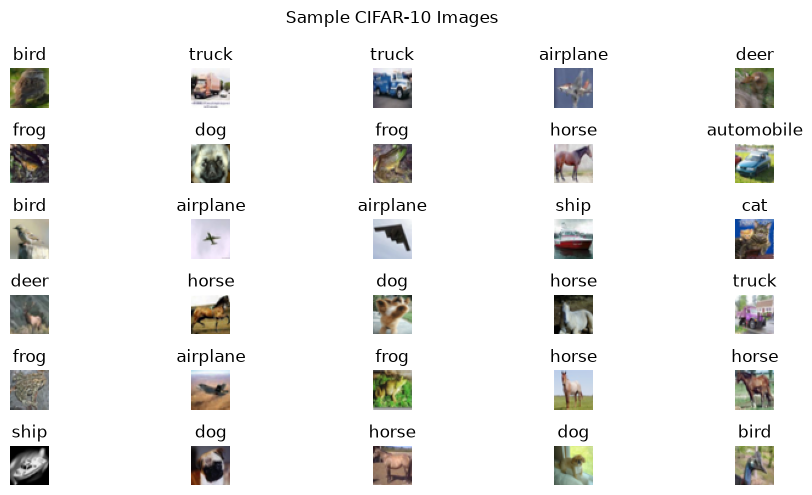

In [7]:
class_names = [
    "airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"
]
plt.figure(figsize=(10, 5))
for i in range(30):
    plt.subplot(6, 5, i + 1)
    plt.imshow(x_small[i])
    plt.title(class_names[y_small[i]])
    plt.axis("off")

plt.suptitle("Sample CIFAR-10 Images")
plt.tight_layout()
plt.show()

In [8]:
x_train, x_val, y_train, y_val = train_test_split( x_small,y_small, test_size=100,
    random_state=SEED,
    stratify=y_small
)
print("Training Images:", x_train.shape)
print("Validation images:", x_val.shape)

Training Images: (400, 32, 32, 3)
Validation images: (100, 32, 32, 3)


In [9]:
def inception_module(x, filters=16):

    b1 = layers.Conv2D(
        filters, 1, padding="same", activation="relu"
    )(x)

    b3 = layers.Conv2D(
        filters, 1, padding="same", activation="relu"
    )(x)
    b3 = layers.Conv2D(
        filters, 3, padding="same", activation="relu"
    )(b3)

    b5 = layers.Conv2D(
        filters, 1, padding="same", activation="relu"
    )(x)
    b5 = layers.Conv2D(
        filters, 5, padding="same", activation="relu"
    )(b5)

    bp = layers.AveragePooling2D(
        pool_size=3, strides=1, padding="same"
    )(x)
    bp = layers.Conv2D(
        filters, 1, padding="same", activation="relu"
    )(bp)


    output = layers.Concatenate()([b1, b3, b5, bp])

    return output

In [10]:
inputs = keras.Input(shape=(32, 32, 3))

x = layers.Conv2D(
    24, 3, padding="same", activation="relu"
)(inputs)

x = layers.MaxPooling2D()(x)

x = layers.Conv2D(
    32, 3, padding="same", activation="relu"
)(x)

x = inception_module(x, filters=16)

x = layers.MaxPooling2D()(x)

x = layers.Conv2D(
    64, 3, padding="same", activation="relu"
)(x)

x = layers.GlobalAveragePooling2D()(x)



outputs = layers.Dense(
    10, activation="softmax"
)(x)

model = keras.Model(inputs, outputs)

model.summary()

print("Total Parameters:", model.count_params())

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)      │ (None, 32, 32, 3)         │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d (Conv2D)               │ (None, 32, 32, 24)        │             672 │ input_layer[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ max_pooling2d (MaxPooling2D)  │ (None, 16, 16, 24)        │               0 │ conv2d[0][0]               │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_1 (Conv2D)             │ (None, 16, 16, 32)        │           6,944 │ max_pooling2d[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_3 (Conv2D)             │ (None, 16, 16, 16)        │             528 │ conv2d_1[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_5 (Conv2D)             │ (None, 16, 16, 16)        │             528 │ conv2d_1[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ average_pooling2d             │ (None, 16, 16, 32)        │               0 │ conv2d_1[0][0]             │
│ (AveragePooling2D)            │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_2 (Conv2D)             │ (None, 16, 16, 16)        │             528 │ conv2d_1[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_4 (Conv2D)             │ (None, 16, 16, 16)        │           2,320 │ conv2d_3[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_6 (Conv2D)             │ (None, 16, 16, 16)        │           6,416 │ conv2d_5[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_7 (Conv2D)             │ (None, 16, 16, 16)        │             528 │ average_pooling2d[0][0]    │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ concatenate (Concatenate)     │ (None, 16, 16, 64)        │               0 │ conv2d_2[0][0],            │
│                               │                           │                 │ conv2d_4[0][0],            │
│                               │                           │                 │ conv2d_6[0][0],            │
│                               │                           │                 │ conv2d_7[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ max_pooling2d_1               │ (None, 8, 8, 64)          │               0 │ concatenate[0][0]          │
│ (MaxPooling2D)                │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_8 (Conv2D)             │ (None, 8, 8, 64)          │          36,928 │ max_pooling2d_1[0][0]      │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ global_average_pooling2d      │ (None, 64)                │               

 Total params: 56,042 (218.91 KB)

 Trainable params: 56,042 (218.91 KB)

 Non-trainable params: 0 (0.00 B)

Total Parameters: 56042


In [11]:
model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [12]:


history = model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=60,
    batch_size=32,
    verbose=1
)

Epoch 1/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 147ms/step - accuracy: 0.1175 - loss: 7.2046 - val_accuracy: 0.1100 - val_loss: 2.8565
Epoch 2/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.1375 - loss: 2.5069 - val_accuracy: 0.1900 - val_loss: 2.3065
Epoch 3/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.1600 - loss: 2.2142 - val_accuracy: 0.1300 - val_loss: 2.2250
Epoch 4/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.2325 - loss: 2.1153 - val_accuracy: 0.1300 - val_loss: 2.1751
Epoch 5/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.2625 - loss: 1.9995 - val_accuracy: 0.1900 - val_loss: 2.1099
Epoch 6/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - accuracy: 0.3200 - loss: 1.8948 - val_accuracy: 0.2700 - val_loss: 2.0201
Epoch 7/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.3200 - loss: 1.8024 - val_accuracy: 0.3000 - val_loss: 1.9918
Epoch 8/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.3525 - loss: 1.7238 - val_accuracy: 0.3000 - 

In [13]:
train_loss, train_acc = model.evaluate(
    x_train, y_train, verbose=0
)

val_loss, val_acc = model.evaluate(
    x_val, y_val, verbose=0
)

print("Training Accuracy:", train_acc)
print("Validation Accuracy:", val_acc)

Training Accuracy: 0.9300000071525574
Validation Accuracy: 0.4000000059604645


In [14]:
clean_loss, clean_acc = model.evaluate(
    x_clean, y_clean, verbose=1
)

print("Clean Test Accuracy:", clean_acc)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.3726 - loss: 2.7878
Clean Test Accuracy: 0.3725999891757965


In [15]:
print("Clean images:", x_clean.shape)
print("Clean labels:", y_clean.shape)
print("Image pixel range:", x_clean.min(), x_clean.max())

Clean images: (10000, 32, 32, 3)
Clean labels: (10000,)
Image pixel range: 0 255


In [16]:
x_shifted = x_clean.astype("float32").copy()

rotation = tf.keras.layers.RandomRotation(
    factor=25 / 360,
    fill_mode="nearest",
    seed=SEED
)

brightness = tf.keras.layers.RandomBrightness(
    factor=0.2,
    value_range=(0, 255),
    seed=SEED
)

contrast = tf.keras.layers.RandomContrast(
    factor=0.2,
    seed=SEED
)

x_shifted = rotation(x_shifted, training=True)
x_shifted = brightness(x_shifted, training=True)
x_shifted = contrast(x_shifted, training=True)

x_shifted = tf.clip_by_value(
    x_shifted, 0, 255
).numpy()

print("Shifted images:", x_shifted.shape)
print("Pixel range:", x_shifted.min(), x_shifted.max())

Shifted images: (10000, 32, 32, 3)
Pixel range: 0.0 255.0


In [17]:
rng = np.random.default_rng(SEED)

for i in range(len(x_shifted)):
    h, w, _ = x_shifted[i].shape

    box_h = h // 2
    box_w = w // 2

    top = rng.integers(0, h - box_h + 1)
    left = rng.integers(0, w - box_w + 1)

    x_shifted[
        i,
        top:top + box_h,
        left:left + box_w,
        :
    ] = 0

print("occlusion successfully")

occlusion successfully


In [18]:
y_shifted = y_clean.copy()

print("Shifted labels:", y_shifted.shape)

Shifted labels: (10000,)


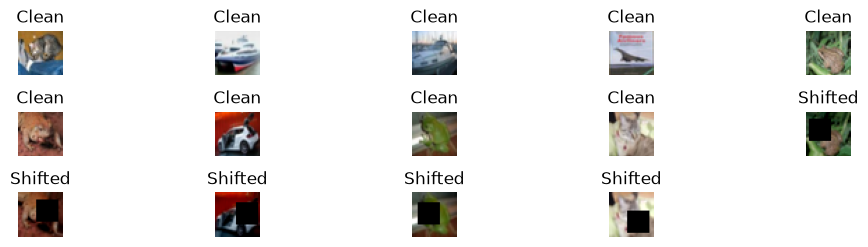

In [19]:
class_names = [
    "airplane", "automobile", "bird", "cat", "deer","dog", "frog", "horse", "ship", "truck"
]
plt.figure(figsize=(10, 5))
for i in range(9):
    plt.subplot(6, 5, i + 1)
    plt.imshow(x_clean[i].astype("uint8"))
    plt.title("Clean")
    plt.axis("off")

    plt.subplot(6, 5, i + 6)
    plt.imshow(np.clip(x_shifted[i], 0, 255).astype("uint8"))
    plt.title("Shifted")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [20]:
shifted_loss, shifted_acc = model.evaluate(
    x_shifted,
    y_shifted,
    verbose=1
)

print("Shifted Test Loss:", shifted_loss)
print("Shifted Test Accuracy:", shifted_acc * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.1265 - loss: 9.9045
Shifted Test Loss: 9.90446662902832
Shifted Test Accuracy: 12.649999558925629 %


In [21]:
x_shifted = x_shifted.astype("float32") 

shifted_loss, shifted_acc = model.evaluate(
    x_shifted, y_shifted, verbose=1
)

print("Shifted Test Accuracy:", shifted_acc)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.1265 - loss: 9.9045
Shifted Test Accuracy: 0.1264999955892563


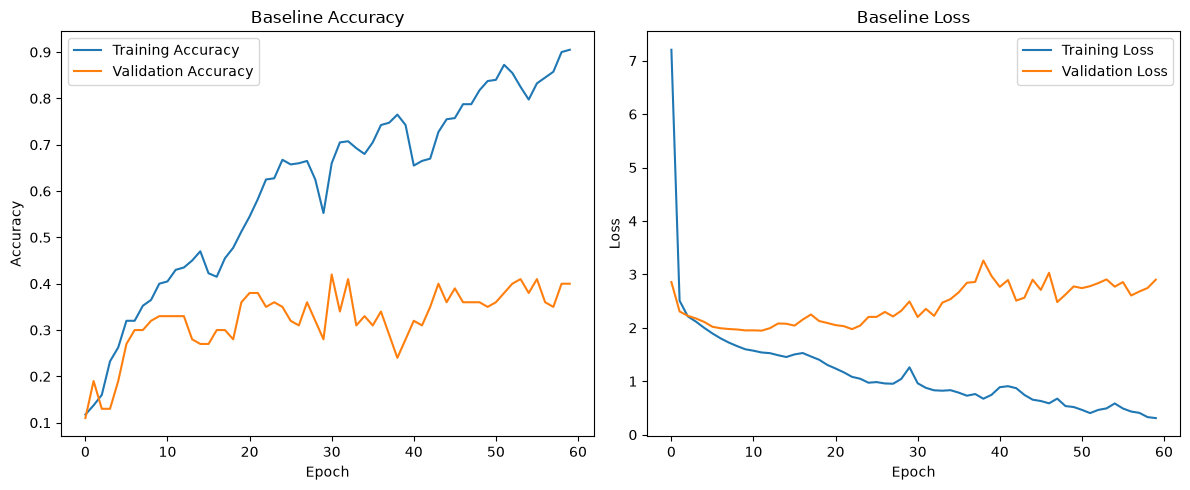

In [22]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)
plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Baseline Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()


plt.subplot(1, 2, 2)

plt.plot(
    history.history["loss"],
    label="Training Loss"
)
plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Baseline Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

**SEED 2026**

In [23]:
results = {
    "Dataset": [
        "Training",
        "Validation",
        "Clean Test",
        "Shifted Test"
    ],
    "Accuracy (%)": [
        train_acc * 100,
        val_acc * 100,
        clean_acc * 100,
        shifted_acc * 100
    ]
}

results_df = pd.DataFrame(results)

results_df["Accuracy (%)"] = results_df["Accuracy (%)"].round(2)

display(results_df)

,Dataset,Accuracy (%)
0,Training,93.00
1,Validation,40.00
2,Clean Test,37.26
3,Shifted Test,12.65


The model learns from the training images. If training accuracy is much higher than validation accuracy it may be overfitting. Shifted images are harder to predict because they have changes like rotation, brightness, and noise. So, the model struggles with new image changes.

**PART B**

In [24]:
tf.keras.utils.set_random_seed(SEED)

data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),

    layers.RandomTranslation(
        height_factor=0.1,
        width_factor=0.1,
        fill_mode="nearest"
    ),

    layers.RandomRotation(
        factor=25 / 360,
        fill_mode="nearest"
    ),

    layers.RandomBrightness(
        factor=0.2,
        value_range=(0, 255)
    ),

    layers.RandomContrast(factor=0.2)
], name="data_augmentation")

In [25]:
inputs = keras.Input(shape=(32, 32, 3))

x = data_augmentation(inputs)

x = layers.Conv2D(
    24, 3, padding="same", activation="relu"
)(x)

x = layers.MaxPooling2D()(x)

x = layers.Conv2D(
    32, 3, padding="same", activation="relu"
)(x)

x = inception_module(x, filters=16)

x = layers.MaxPooling2D()(x)

x = layers.Conv2D(
    64, 3, padding="same", activation="relu"
)(x)

x = layers.GlobalAveragePooling2D()(x)

outputs = layers.Dense(
    10, activation="softmax"
)(x)

model_aug = keras.Model(inputs, outputs)

model_aug.summary()

print("Trainable parameters:",
      sum(np.prod(w.shape) for w in model_aug.trainable_weights))

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)    │ (None, 32, 32, 3)         │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ data_augmentation             │ (None, 32, 32, 3)         │               0 │ input_layer_1[0][0]        │
│ (Sequential)                  │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_9 (Conv2D)             │ (None, 32, 32, 24)        │             672 │ data_augmentation[0][0]    │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ max_pooling2d_2               │ (None, 16, 16, 24)        │               0 │ conv2d_9[0][0]             │
│ (MaxPooling2D)                │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_10 (Conv2D)            │ (None, 16, 16, 32)        │           6,944 │ max_pooling2d_2[0][0]      │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_12 (Conv2D)            │ (None, 16, 16, 16)        │             528 │ conv2d_10[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_14 (Conv2D)            │ (None, 16, 16, 16)        │             528 │ conv2d_10[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ average_pooling2d_1           │ (None, 16, 16, 32)        │               0 │ conv2d_10[0][0]            │
│ (AveragePooling2D)            │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_11 (Conv2D)            │ (None, 16, 16, 16)        │             528 │ conv2d_10[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_13 (Conv2D)            │ (None, 16, 16, 16)        │           2,320 │ conv2d_12[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_15 (Conv2D)            │ (None, 16, 16, 16)        │           6,416 │ conv2d_14[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_16 (Conv2D)            │ (None, 16, 16, 16)        │             528 │ average_pooling2d_1[0][0]  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ concatenate_1 (Concatenate)   │ (None, 16, 16, 64)        │               0 │ conv2d_11[0][0],           │
│                               │                           │                 │ conv2d_13[0][0],           │
│                               │                           │                 │ conv2d_15[0][0],           │
│                               │                           │                 │ conv2d_16[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ max_pooling2d_3               │ (None, 8, 8, 64)          │               0 │ concatenate_1[0][0]        │
│ (MaxPooling2D)                │                           │               

 Total params: 56,042 (218.91 KB)

 Trainable params: 56,042 (218.91 KB)

 Non-trainable params: 0 (0.00 B)

Trainable parameters: 56042


In [26]:
model_aug.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [27]:
history_aug = model_aug.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=60,
    batch_size=32,
    verbose=1
)

Epoch 1/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 5s 191ms/step - accuracy: 0.1000 - loss: 11.1653 - val_accuracy: 0.1500 - val_loss: 2.9696
Epoch 2/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.1125 - loss: 2.6179 - val_accuracy: 0.1300 - val_loss: 2.2673
Epoch 3/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - accuracy: 0.1200 - loss: 2.2912 - val_accuracy: 0.2000 - val_loss: 2.2530
Epoch 4/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - accuracy: 0.1575 - loss: 2.2361 - val_accuracy: 0.2600 - val_loss: 2.2157
Epoch 5/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.1625 - loss: 2.1782 - val_accuracy: 0.2700 - val_loss: 2.1709
Epoch 6/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - accuracy: 0.2050 - loss: 2.1243 - val_accuracy: 0.1900 - val_loss: 2.1718
Epoch 7/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.2175 - loss: 2.0861 - val_accuracy: 0.2100 - val_loss: 2.0759
Epoch 8/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - accuracy: 0.2550 - loss: 1.9816 - val_accuracy: 0.2100 -

In [28]:
train_loss_aug, train_acc_aug = model_aug.evaluate(
    x_train, y_train, verbose=0
)

val_loss_aug, val_acc_aug = model_aug.evaluate(
    x_val, y_val, verbose=0
)

clean_loss_aug, clean_acc_aug = model_aug.evaluate(
    x_clean, y_clean, verbose=1
)

print("Training Accuracy:", train_acc_aug * 100, "%")
print("Validation Accuracy:", val_acc_aug * 100, "%")
print("Clean Test Accuracy:", clean_acc_aug * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.3722 - loss: 2.0262
Training Accuracy: 60.25000214576721 %
Validation Accuracy: 43.99999976158142 %
Clean Test Accuracy: 37.220001220703125 %


In [29]:
shifted_loss_aug, shifted_acc_aug = model_aug.evaluate(
    x_shifted, y_shifted, verbose=1
)

print("Synthetic Shifted Test Accuracy:",
      shifted_acc_aug * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.2525 - loss: 2.6829
Synthetic Shifted Test Accuracy: 25.24999976158142 %


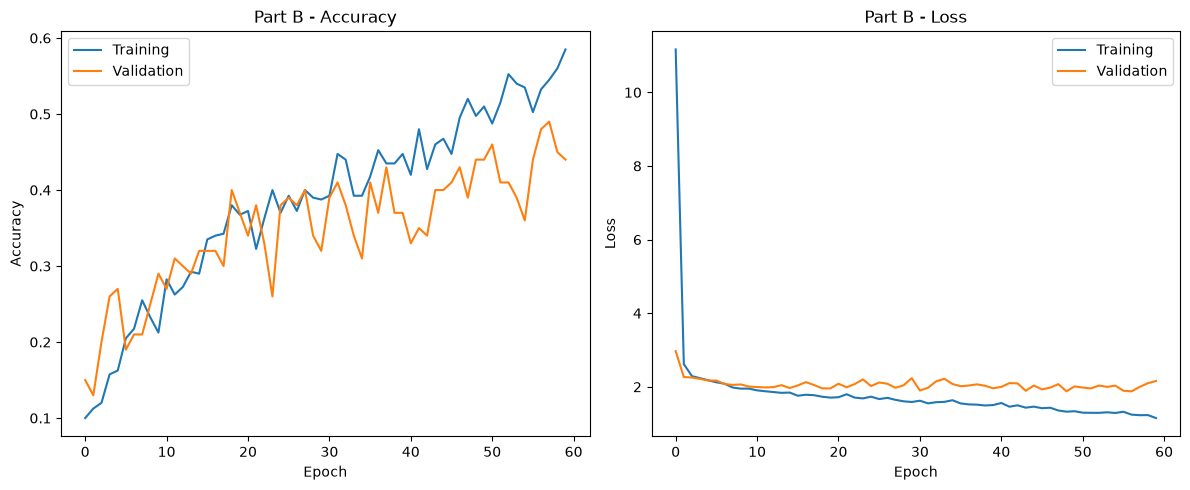

In [30]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_aug.history["accuracy"],
         label="Training")
plt.plot(history_aug.history["val_accuracy"],
         label="Validation")
plt.title("Part B - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_aug.history["loss"],
         label="Training")
plt.plot(history_aug.history["val_loss"],
         label="Validation")
plt.title("Part B - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

 ## Would vertical flip help or hurt on this dataset? Why?
 Vertical flip may hurt accuracy because most of theobjects normally appear upright.Horizontal flip is more useful because it changes the left right direction without changing the objects class.
 ##  If you augment with rotation up to ±90° but the test only has ±25°, what is the trade off?
 Large rotations may Improve performance on rotated imagebut they can also create unusual images and make training harder. Since test images rotate only up to ±25 smaller rotations are more suitable.
 ## Why can too much augmentation reduce accuracy on such a small model?
 Too much augmentation can make images too difficult or unrealistic. A small model trained on only 400 images may struggle to learn useful features. Therefore, we should use suitable augmentation and check its performance on validation data.

**PART C**

In [31]:
def conv_bn_relu(x, filters, kernel_size):
    x = layers.Conv2D(
        filters,
        kernel_size,
        padding="same",
        use_bias=False
    )(x)

    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    return x


def inception_c(x, filters=16):

    b1 = conv_bn_relu(x, filters, 1)

    b3 = conv_bn_relu(x, filters, 1)
    b3 = conv_bn_relu(b3, filters, 3)

    b5 = conv_bn_relu(x, filters, 1)
    b5 = conv_bn_relu(b5, filters, 5)

    bp = layers.AveragePooling2D(
        pool_size=3, strides=1, padding="same"
    )(x)
    bp = conv_bn_relu(bp, filters, 1)

    return layers.Concatenate()([b1, b3, b5, bp])


inputs = keras.Input(shape=(32, 32, 3))

x = data_augmentation(inputs)

x = conv_bn_relu(x, 24, 3)
x = layers.MaxPooling2D()(x)

x = conv_bn_relu(x, 32, 3)
x = inception_c(x, filters=16)

x = layers.MaxPooling2D()(x)
x = conv_bn_relu(x, 64, 3)

x = layers.GlobalAveragePooling2D()(x)

# Dropout 
x = layers.Dropout(0.4)(x)

outputs = layers.Dense(10, activation="softmax")(x)

model_c = keras.Model(inputs, outputs)

model_c.summary()
print("Trainable parameters:", model_c.count_params())

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)    │ (None, 32, 32, 3)         │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ data_augmentation             │ (None, 32, 32, 3)         │               0 │ input_layer_3[0][0]        │
│ (Sequential)                  │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_18 (Conv2D)            │ (None, 32, 32, 24)        │             648 │ data_augmentation[1][0]    │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization           │ (None, 32, 32, 24)        │              96 │ conv2d_18[0][0]            │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation (Activation)       │ (None, 32, 32, 24)        │               0 │ batch_normalization[0][0]  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ max_pooling2d_4               │ (None, 16, 16, 24)        │               0 │ activation[0][0]           │
│ (MaxPooling2D)                │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_19 (Conv2D)            │ (None, 16, 16, 32)        │           6,912 │ max_pooling2d_4[0][0]      │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_1         │ (None, 16, 16, 32)        │             128 │ conv2d_19[0][0]            │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation_1 (Activation)     │ (None, 16, 16, 32)        │               0 │ batch_normalization_1[0][… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_21 (Conv2D)            │ (None, 16, 16, 16)        │             512 │ activation_1[0][0]         │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_23 (Conv2D)            │ (None, 16, 16, 16)        │             512 │ activation_1[0][0]         │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_3         │ (None, 16, 16, 16)        │              64 │ conv2d_21[0][0]            │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_5         │ (None, 16, 16, 16)        │              64 │ conv2d_23[0][0]            │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation_3 (Activation)     │ (None, 16, 16, 16)        │               0 │ batch_normalization_3[0][… │
├───────────────────────────────┼───────────────────────────┼───────────────

 Total params: 56,690 (221.45 KB)

 Trainable params: 56,258 (219.76 KB)

 Non-trainable params: 432 (1.69 KB)

Trainable parameters: 56690


In [32]:
y_train_onehot = keras.utils.to_categorical(y_train, 10)
y_val_onehot = keras.utils.to_categorical(y_val, 10)

In [33]:
model_c.compile(
    optimizer=keras.optimizers.AdamW(
        learning_rate=0.001,
        weight_decay=1e-4
    ),
    loss=keras.losses.CategoricalCrossentropy(
        label_smoothing=0.05
    ),
    metrics=["accuracy"]
)

In [34]:
callbacks_c = [

    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True,
        verbose=1
    )
]

In [35]:
history_c = model_c.fit(
    x_train,
    y_train_onehot,
    validation_data=(x_val, y_val_onehot),
    epochs=60,
    batch_size=32,
    callbacks=callbacks_c,
    verbose=1
)

Epoch 1/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 9s 363ms/step - accuracy: 0.1575 - loss: 2.3722 - val_accuracy: 0.1000 - val_loss: 3.7699
Epoch 2/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 53ms/step - accuracy: 0.2275 - loss: 2.1054 - val_accuracy: 0.1000 - val_loss: 3.6784
Epoch 3/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 53ms/step - accuracy: 0.2550 - loss: 2.0371 - val_accuracy: 0.1300 - val_loss: 3.1890
Epoch 4/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 54ms/step - accuracy: 0.2800 - loss: 1.9599 - val_accuracy: 0.1400 - val_loss: 2.8930
Epoch 5/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 55ms/step - accuracy: 0.2850 - loss: 1.9532 - val_accuracy: 0.1300 - val_loss: 2.7813
Epoch 6/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 54ms/step - accuracy: 0.3225 - loss: 1.8682 - val_accuracy: 0.1300 - val_loss: 2.3137
Epoch 7/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 55ms/step - accuracy: 0.3125 - loss: 1.8751 - val_accuracy: 0.1800 - val_loss: 2.1830
Epoch 8/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 56ms/step - accuracy: 0.3425 - loss: 1.8354 - val_accuracy: 0.2600 - 

In [36]:
train_loss_c, train_acc_c = model_c.evaluate(
    x_train, y_train_onehot, verbose=0
)

val_loss_c, val_acc_c = model_c.evaluate(
    x_val, y_val_onehot, verbose=0
)

clean_loss_c, clean_acc_c = model_c.evaluate(
    x_clean, keras.utils.to_categorical(y_clean, 10),
    verbose=1
)

print("Training Accuracy:", train_acc_c * 100, "%")
print("Validation Accuracy:", val_acc_c * 100, "%")
print("Clean Test Accuracy:", clean_acc_c * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.3100 - loss: 1.9435
Training Accuracy: 37.25000023841858 %
Validation Accuracy: 31.999999284744263 %
Clean Test Accuracy: 31.00000023841858 %


In [37]:
y_shifted_onehot = keras.utils.to_categorical(y_shifted, 10)

shifted_loss_c, shifted_acc_c = model_c.evaluate(
    x_shifted, y_shifted_onehot, verbose=1
)

print("Synthetic Shifted Accuracy:", shifted_acc_c * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.2248 - loss: 2.1475
Synthetic Shifted Accuracy: 22.48000055551529 %


### Regularization and Training Design

Batch Normalization is used after convolutional layers to make training more stable. Dropout is added after Global Average Pooling to help prevent overfitting. AdamW uses weight decay to prevent the model's weights from becoming too large. Label smoothing helps the model make less overconfident predictions. EarlyStopping stops training when the validation loss does not improve and restores the best model weights.

**PART D**

In [38]:
def build_model(augmentation=None):
    inputs = keras.Input(shape=(32, 32, 3))

    x = inputs

    if augmentation is not None:
        x = augmentation(x)

    x = layers.Conv2D(
        24, 3, padding="same", activation="relu"
    )(x)
    x = layers.MaxPooling2D()(x)

    x = layers.Conv2D(
        32, 3, padding="same", activation="relu"
    )(x)

    x = inception_module(x, filters=16)
    x = layers.MaxPooling2D()(x)

    x = layers.Conv2D(
        64, 3, padding="same", activation="relu"
    )(x)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)

    outputs = layers.Dense(
        10, activation="softmax"
    )(x)

    model = keras.Model(inputs, outputs)

    model.compile(
        optimizer=keras.optimizers.Adam(0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [39]:

geometric_aug = keras.Sequential([
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(25 / 360)
])

tf.keras.utils.set_random_seed(42)

model_geo = build_model(geometric_aug)

history_geo = model_geo.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=60,
    batch_size=32,
    verbose=1
)

val_loss, val_acc = model_geo.evaluate(
    x_val, y_val, verbose=0
)

print("Geometric validation accuracy:", val_acc)

Epoch 1/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 7s 203ms/step - accuracy: 0.0900 - loss: 5.7054 - val_accuracy: 0.1000 - val_loss: 2.3301
Epoch 2/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.1325 - loss: 2.3044 - val_accuracy: 0.1500 - val_loss: 2.2385
Epoch 3/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - accuracy: 0.1475 - loss: 2.2251 - val_accuracy: 0.1500 - val_loss: 2.2028
Epoch 4/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.1575 - loss: 2.1800 - val_accuracy: 0.2000 - val_loss: 2.1786
Epoch 5/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.2075 - loss: 2.1293 - val_accuracy: 0.2300 - val_loss: 2.1067
Epoch 6/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - accuracy: 0.2175 - loss: 2.0962 - val_accuracy: 0.2200 - val_loss: 2.0980
Epoch 7/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - accuracy: 0.2200 - loss: 2.0825 - val_accuracy: 0.2800 - val_loss: 2.0996
Epoch 8/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.2550 - loss: 2.0566 - val_accuracy: 0.2300 - 

In [40]:


results = [
    "No augmentation",
    "Geometric only",
    "Photometric only",
    "Geometric + photometric",
    "+ Cutout / Random Erasing",
    "+ Mixup / CutMix + label smoothing",
    "Final model"
]

df_results = pd.DataFrame({
    "Configuration": results,
    "Val Acc": [None] * 7,
    "Clean Test": [None] * 7,
    "Shifted Test (Mean ± Std)": [None] * 7
})

display(df_results)

,Configuration,Val Acc,Clean Test,Shifted Test (Mean ± Std)
0,No augmentation,None,None,None
1,Geometric only,None,None,None
2,Photometric only,None,None,None
3,Geometric + photometric,None,None,None
4,+ Cutout / Random Erasing,None,None,None
5,+ Mixup / CutMix + label smoothing,None,None,None
6,Final model,None,None,None


In [41]:
_, val_acc = model_geo.evaluate(
    x_val, y_val, verbose=0
)

_, clean_acc = model_geo.evaluate(
    x_clean, y_clean, verbose=0
)

print("Validation Accuracy:", round(val_acc * 100, 2), "%")
print("Clean Test Accuracy:", round(clean_acc * 100, 2), "%")

Validation Accuracy: 39.0 %
Clean Test Accuracy: 39.44 %


In [42]:
_, shifted_acc = model_geo.evaluate(
    x_shifted, y_shifted, verbose=0
)

print("Shifted Test Accuracy:",
      round(shifted_acc * 100, 2), "%")

Shifted Test Accuracy: 14.33 %


In [43]:
_, shifted_acc_geo = model_geo.evaluate(
    x_shifted,
    y_shifted,
    verbose=0
)

print("Shifted accuracy:", shifted_acc_geo)
print("Shifted accuracy (%):", shifted_acc_geo * 100)

Shifted accuracy: 0.14329999685287476
Shifted accuracy (%): 14.329999685287476


In [44]:
df_results.loc[1, "Val Acc"] = round(
    val_acc * 100, 2
)

df_results.loc[1, "Clean Test"] = round(
    clean_acc * 100, 2
)
df_results.loc[1, "Shifted Test (Mean ± Std)"] = (
    f"{shifted_acc_geo * 100:.2f}% (seed 123)"
)
display(df_results)

,Configuration,Val Acc,Clean Test,Shifted Test (Mean ± Std)
0,No augmentation,None,None,None
1,Geometric only,39.0,39.44,14.33% (seed 123)
2,Photometric only,None,None,None
3,Geometric + photometric,None,None,None
4,+ Cutout / Random Erasing,None,None,None
5,+ Mixup / CutMix + label smoothing,None,None,None
6,Final model,None,None,None


In [45]:
_, shifted_acc_geo = model_geo.evaluate(
    x_shifted,
    y_shifted,
    verbose=0
)

print("Shifted accuracy:", shifted_acc_geo)
print("Shifted accuracy (%):", shifted_acc_geo * 100)

Shifted accuracy: 0.14329999685287476
Shifted accuracy (%): 14.329999685287476


In [46]:
tf.keras.utils.set_random_seed(SEED)

photometric_aug = keras.Sequential([
    layers.RandomBrightness(
        factor=0.2,
        value_range=(0, 255)
    ),
    layers.RandomContrast(factor=0.2)
])

In [47]:
model_photo = build_model(photometric_aug)

history_photo = model_photo.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=60,
    batch_size=32,
    verbose=1
)

Epoch 1/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 5s 229ms/step - accuracy: 0.1075 - loss: 8.1152 - val_accuracy: 0.1400 - val_loss: 2.3947
Epoch 2/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.1175 - loss: 2.3267 - val_accuracy: 0.1700 - val_loss: 2.2881
Epoch 3/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.1575 - loss: 2.2846 - val_accuracy: 0.0700 - val_loss: 2.2720
Epoch 4/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.1475 - loss: 2.2488 - val_accuracy: 0.1000 - val_loss: 2.2512
Epoch 5/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.1450 - loss: 2.2310 - val_accuracy: 0.1300 - val_loss: 2.2409
Epoch 6/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.1850 - loss: 2.2111 - val_accuracy: 0.1100 - val_loss: 2.2202
Epoch 7/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.1950 - loss: 2.2008 - val_accuracy: 0.1800 - val_loss: 2.2051
Epoch 8/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.2100 - loss: 2.1516 - val_accuracy: 0.2000 - 

In [48]:
_, val_acc = model_photo.evaluate(
    x_val, y_val, verbose=0
)

_, clean_acc = model_photo.evaluate(
    x_clean, y_clean, verbose=0
)

_, shifted_acc = model_photo.evaluate(
    x_shifted, y_shifted, verbose=0
)

print("Validation Accuracy:", round(val_acc * 100, 2), "%")
print("Clean Test Accuracy:", round(clean_acc * 100, 2), "%")
print("Shifted Test Accuracy:", round(shifted_acc * 100, 2), "%")

Validation Accuracy: 35.0 %
Clean Test Accuracy: 35.77 %
Shifted Test Accuracy: 21.27 %


In [49]:
df_results.loc[2, "Val Acc"] = round(val_acc * 100, 2)

df_results.loc[2, "Clean Test"] = round(clean_acc * 100, 2)

df_results.loc[2, "Shifted Test (Mean ± Std)"] = (
    f"{shifted_acc * 100:.2f}% (seed 123)"
)

display(df_results)

,Configuration,Val Acc,Clean Test,Shifted Test (Mean ± Std)
0,No augmentation,None,None,None
1,Geometric only,39.0,39.44,14.33% (seed 123)
2,Photometric only,35.0,35.77,21.27% (seed 123)
3,Geometric + photometric,None,None,None
4,+ Cutout / Random Erasing,None,None,None
5,+ Mixup / CutMix + label smoothing,None,None,None
6,Final model,None,None,None


In [50]:
tf.keras.utils.set_random_seed(SEED)

combined_aug = keras.Sequential([
    layers.RandomTranslation(
        0.1, 0.1,
        fill_mode="nearest"
    ),

    layers.RandomFlip("horizontal"),

    layers.RandomRotation(
        25 / 360,
        fill_mode="nearest"
    ),

    layers.RandomBrightness(
        factor=0.2,
        value_range=(0, 255)
    ),

    layers.RandomContrast(
        factor=0.2
    )
])

In [51]:
model_combined = build_model(combined_aug)

history_combined = model_combined.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=60,
    batch_size=32,
    verbose=1
)

Epoch 1/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 5s 195ms/step - accuracy: 0.1275 - loss: 9.4687 - val_accuracy: 0.1400 - val_loss: 2.6357
Epoch 2/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - accuracy: 0.1175 - loss: 2.5463 - val_accuracy: 0.1800 - val_loss: 2.2713
Epoch 3/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - accuracy: 0.1475 - loss: 2.2679 - val_accuracy: 0.2000 - val_loss: 2.2403
Epoch 4/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - accuracy: 0.1475 - loss: 2.2438 - val_accuracy: 0.2100 - val_loss: 2.2017
Epoch 5/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - accuracy: 0.1725 - loss: 2.2020 - val_accuracy: 0.2100 - val_loss: 2.1595
Epoch 6/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - accuracy: 0.1675 - loss: 2.1982 - val_accuracy: 0.1600 - val_loss: 2.1134
Epoch 7/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - accuracy: 0.1700 - loss: 2.1850 - val_accuracy: 0.2300 - val_loss: 2.0962
Epoch 8/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - accuracy: 0.2150 - loss: 2.1239 - val_accuracy: 0.2700 - 

In [52]:
_, val_acc = model_combined.evaluate(
    x_val, y_val, verbose=0
)

_, clean_acc = model_combined.evaluate(
    x_clean, y_clean, verbose=0
)

_, shifted_acc = model_combined.evaluate(
    x_shifted, y_shifted, verbose=0
)

print("Validation Accuracy:", round(val_acc * 100, 2), "%")
print("Clean Test Accuracy:", round(clean_acc * 100, 2), "%")
print("Shifted Test Accuracy:", round(shifted_acc * 100, 2), "%")

Validation Accuracy: 39.0 %
Clean Test Accuracy: 38.44 %
Shifted Test Accuracy: 17.0 %


In [53]:
df_results.loc[3, "Val Acc"] = round(
    val_acc * 100, 2
)

df_results.loc[3, "Clean Test"] = round(
    clean_acc * 100, 2
)

df_results.loc[3, "Shifted Test (Mean ± Std)"] = (
    f"{shifted_acc * 100:.2f}% (seed 123)"
)

display(df_results)

,Configuration,Val Acc,Clean Test,Shifted Test (Mean ± Std)
0,No augmentation,None,None,None
1,Geometric only,39.0,39.44,14.33% (seed 123)
2,Photometric only,35.0,35.77,21.27% (seed 123)
3,Geometric + photometric,39.0,38.44,17.00% (seed 123)
4,+ Cutout / Random Erasing,None,None,None
5,+ Mixup / CutMix + label smoothing,None,None,None
6,Final model,None,None,None


In [54]:
def apply_cutout(images):
    batch_size = tf.shape(images)[0]

    top = tf.random.uniform(
        [batch_size], 0, 17, dtype=tf.int32
    )
    left = tf.random.uniform(
        [batch_size], 0, 17, dtype=tf.int32
    )

    rows = tf.range(32)[None, :, None]
    cols = tf.range(32)[None, None, :]

    mask = (
        (rows < top[:, None, None]) |
        (rows >= (top + 16)[:, None, None]) |
        (cols < left[:, None, None]) |
        (cols >= (left + 16)[:, None, None])
    )

    mask = tf.cast(mask[..., None], images.dtype)

    return images * mask

In [55]:
tf.keras.utils.set_random_seed(SEED)

cutout_aug = keras.Sequential([
    combined_aug,
    layers.Lambda(apply_cutout)
])

In [56]:
model_cutout = build_model(cutout_aug)

history_cutout = model_cutout.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=60,
    batch_size=32,
    verbose=1
)

Epoch 1/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 5s 205ms/step - accuracy: 0.0975 - loss: 6.3443 - val_accuracy: 0.1000 - val_loss: 2.3654
Epoch 2/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - accuracy: 0.1025 - loss: 2.3267 - val_accuracy: 0.1500 - val_loss: 2.2721
Epoch 3/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - accuracy: 0.1100 - loss: 2.2802 - val_accuracy: 0.1400 - val_loss: 2.2398
Epoch 4/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - accuracy: 0.1250 - loss: 2.2464 - val_accuracy: 0.1900 - val_loss: 2.2088
Epoch 5/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - accuracy: 0.1475 - loss: 2.2560 - val_accuracy: 0.1700 - val_loss: 2.2330
Epoch 6/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - accuracy: 0.1150 - loss: 2.2528 - val_accuracy: 0.1800 - val_loss: 2.2308
Epoch 7/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - accuracy: 0.1550 - loss: 2.2279 - val_accuracy: 0.1700 - val_loss: 2.2133
Epoch 8/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - accuracy: 0.1725 - loss: 2.2215 - val_accuracy: 0.1700 - 

In [57]:
_, val_acc = model_cutout.evaluate(
    x_val, y_val, verbose=0
)

_, clean_acc = model_cutout.evaluate(
    x_clean, y_clean, verbose=0
)

_, shifted_acc = model_cutout.evaluate(
    x_shifted, y_shifted, verbose=0
)

print("Validation Accuracy:", round(val_acc * 100, 2), "%")
print("Clean Test Accuracy:", round(clean_acc * 100, 2), "%")
print("Synthetic Shifted Accuracy:", round(shifted_acc * 100, 2), "%")

Validation Accuracy: 26.0 %
Clean Test Accuracy: 31.5 %
Synthetic Shifted Accuracy: 27.27 %


In [58]:
df_results.loc[4, "Val Acc"] = round(val_acc * 100, 2)
df_results.loc[4, "Clean Test"] = round(clean_acc * 100, 2)

df_results.loc[4, "Shifted Test (Mean ± Std)"] = (
    f"{shifted_acc * 100:.2f}% (seed 123)"
)

display(df_results)

,Configuration,Val Acc,Clean Test,Shifted Test (Mean ± Std)
0,No augmentation,None,None,None
1,Geometric only,39.0,39.44,14.33% (seed 123)
2,Photometric only,35.0,35.77,21.27% (seed 123)
3,Geometric + photometric,39.0,38.44,17.00% (seed 123)
4,+ Cutout / Random Erasing,26.0,31.5,27.27% (seed 123)
5,+ Mixup / CutMix + label smoothing,None,None,None
6,Final model,None,None,None


In [59]:
def mixup_batch(images, labels, alpha=0.2):
    lam = np.random.beta(alpha, alpha)

    indices = tf.random.shuffle(
        tf.range(tf.shape(images)[0])
    )

    mixed_images = (
        lam * images +
        (1 - lam) * tf.gather(images, indices)
    )

    mixed_labels = (
        lam * labels +
        (1 - lam) * tf.gather(labels, indices)
    )

    return mixed_images, mixed_labels

In [60]:
y_train_onehot = keras.utils.to_categorical(
    y_train, 10
)

y_val_onehot = keras.utils.to_categorical(
    y_val, 10
)

In [61]:
tf.keras.utils.set_random_seed(SEED)

model_mixup = build_model(combined_aug)

model_mixup.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss=keras.losses.CategoricalCrossentropy(
        label_smoothing=0.1
    ),
    metrics=["accuracy"]
)

In [62]:
_, val_acc = model_mixup.evaluate(
    x_val, y_val_onehot, verbose=0
)

_, clean_acc = model_mixup.evaluate(
    x_clean,
    keras.utils.to_categorical(y_clean, 10),
    verbose=0
)

_, shifted_acc = model_mixup.evaluate(
    x_shifted,
    keras.utils.to_categorical(y_shifted, 10),
    verbose=0
)

print("Validation Accuracy:", round(val_acc * 100, 2), "%")
print("Clean Test Accuracy:", round(clean_acc * 100, 2), "%")
print("Synthetic Shifted Accuracy:", round(shifted_acc * 100, 2), "%")

Validation Accuracy: 10.0 %
Clean Test Accuracy: 10.01 %
Synthetic Shifted Accuracy: 10.24 %


In [63]:
df_results.loc[5, "Val Acc"] = round(val_acc * 100, 2)
df_results.loc[5, "Clean Test"] = round(clean_acc * 100, 2)

df_results.loc[5, "Shifted Test (Mean ± Std)"] = (
    f"{shifted_acc * 100:.2f}% (seed 123)"
)

display(df_results)

,Configuration,Val Acc,Clean Test,Shifted Test (Mean ± Std)
0,No augmentation,None,None,None
1,Geometric only,39.0,39.44,14.33% (seed 123)
2,Photometric only,35.0,35.77,21.27% (seed 123)
3,Geometric + photometric,39.0,38.44,17.00% (seed 123)
4,+ Cutout / Random Erasing,26.0,31.5,27.27% (seed 123)
5,+ Mixup / CutMix + label smoothing,10.0,10.01,10.24% (seed 123)
6,Final model,None,None,None


In [64]:
tf.keras.utils.set_random_seed(SEED)

model_baseline = build_model(augmentation=None)

history_baseline = model_baseline.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=60,
    batch_size=32,
    verbose=1
)

Epoch 1/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 181ms/step - accuracy: 0.0925 - loss: 7.3338 - val_accuracy: 0.1100 - val_loss: 2.3543
Epoch 2/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.1150 - loss: 2.3127 - val_accuracy: 0.2000 - val_loss: 2.2371
Epoch 3/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.1325 - loss: 2.2460 - val_accuracy: 0.1800 - val_loss: 2.1716
Epoch 4/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.1700 - loss: 2.1916 - val_accuracy: 0.1900 - val_loss: 2.1401
Epoch 5/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.1900 - loss: 2.1744 - val_accuracy: 0.1800 - val_loss: 2.1553
Epoch 6/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - accuracy: 0.1750 - loss: 2.1584 - val_accuracy: 0.2200 - val_loss: 2.1295
Epoch 7/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.2325 - loss: 2.1065 - val_accuracy: 0.1900 - val_loss: 2.1045
Epoch 8/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.2400 - loss: 2.0918 - val_accuracy: 0.2600 - 

In [65]:
_, val_acc_base = model_baseline.evaluate(
    x_val, y_val, verbose=0
)

_, clean_acc_base = model_baseline.evaluate(
    x_clean, y_clean, verbose=0
)

_, shifted_acc_base = model_baseline.evaluate(
    x_shifted, y_shifted, verbose=0
)

print("Validation Accuracy:", round(val_acc_base * 100, 2), "%")
print("Clean Test Accuracy:", round(clean_acc_base * 100, 2), "%")
print("Synthetic Shifted Accuracy:", round(shifted_acc_base * 100, 2), "%")

Validation Accuracy: 37.0 %
Clean Test Accuracy: 37.91 %
Synthetic Shifted Accuracy: 17.98 %


In [66]:
df_results.loc[0, "Val Acc"] = round(
    val_acc_base * 100, 2
)

df_results.loc[0, "Clean Test"] = round(
    clean_acc_base * 100, 2
)

df_results.loc[0, "Shifted Test (Mean ± Std)"] = (
    f"{shifted_acc_base * 100:.2f}% (seed 123)"
)

display(df_results)

,Configuration,Val Acc,Clean Test,Shifted Test (Mean ± Std)
0,No augmentation,37.0,37.91,17.98% (seed 123)
1,Geometric only,39.0,39.44,14.33% (seed 123)
2,Photometric only,35.0,35.77,21.27% (seed 123)
3,Geometric + photometric,39.0,38.44,17.00% (seed 123)
4,+ Cutout / Random Erasing,26.0,31.5,27.27% (seed 123)
5,+ Mixup / CutMix + label smoothing,10.0,10.01,10.24% (seed 123)
6,Final model,None,None,None


In [67]:
tf.keras.utils.set_random_seed(SEED)

final_augmentation = keras.Sequential([
    layers.RandomTranslation(
        0.1, 0.1,
        fill_mode="nearest"
    ),

    layers.RandomFlip("horizontal"),

    layers.RandomRotation(
        25 / 360,
        fill_mode="nearest"
    ),

    layers.RandomBrightness(
        factor=0.2,
        value_range=(0, 255)
    ),

    layers.RandomContrast(factor=0.2),

    layers.Lambda(apply_cutout)
])

In [68]:
model_final = build_model(final_augmentation)

history_final = model_final.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=60,
    batch_size=32,
    verbose=1
)

Epoch 1/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 6s 236ms/step - accuracy: 0.1075 - loss: 8.2906 - val_accuracy: 0.1300 - val_loss: 2.5613
Epoch 2/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - accuracy: 0.1250 - loss: 2.4906 - val_accuracy: 0.0800 - val_loss: 2.2930
Epoch 3/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - accuracy: 0.1350 - loss: 2.2958 - val_accuracy: 0.1000 - val_loss: 2.2839
Epoch 4/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - accuracy: 0.1225 - loss: 2.2772 - val_accuracy: 0.1000 - val_loss: 2.2728
Epoch 5/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - accuracy: 0.1225 - loss: 2.2724 - val_accuracy: 0.1500 - val_loss: 2.2495
Epoch 6/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - accuracy: 0.1225 - loss: 2.2671 - val_accuracy: 0.1900 - val_loss: 2.2264
Epoch 7/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step - accuracy: 0.1175 - loss: 2.2564 - val_accuracy: 0.1900 - val_loss: 2.2059
Epoch 8/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - accuracy: 0.1625 - loss: 2.2134 - val_accuracy: 0.1900 - 

In [69]:
_, final_val_acc = model_final.evaluate(
    x_val, y_val, verbose=0
)

_, final_clean_acc = model_final.evaluate(
    x_clean, y_clean, verbose=0
)

_, final_shifted_acc = model_final.evaluate(
    x_shifted, y_shifted, verbose=0
)

print("Final Validation Accuracy:",
      round(final_val_acc * 100, 2), "%")

print("Final Clean Test Accuracy:",
      round(final_clean_acc * 100, 2), "%")

print("Final Synthetic Shifted Accuracy:",
      round(final_shifted_acc * 100, 2), "%")

Final Validation Accuracy: 35.0 %
Final Clean Test Accuracy: 30.69 %
Final Synthetic Shifted Accuracy: 26.84 %


In [70]:
df_results.loc[6, "Val Acc"] = round(
    final_val_acc * 100, 2
)

df_results.loc[6, "Clean Test"] = round(
    final_clean_acc * 100, 2
)

df_results.loc[6, "Shifted Test (Mean ± Std)"] = (
    f"{final_shifted_acc * 100:.2f}% (seed 123)"
)

display(df_results)

,Configuration,Val Acc,Clean Test,Shifted Test (Mean ± Std)
0,No augmentation,37.0,37.91,17.98% (seed 123)
1,Geometric only,39.0,39.44,14.33% (seed 123)
2,Photometric only,35.0,35.77,21.27% (seed 123)
3,Geometric + photometric,39.0,38.44,17.00% (seed 123)
4,+ Cutout / Random Erasing,26.0,31.5,27.27% (seed 123)
5,+ Mixup / CutMix + label smoothing,10.0,10.01,10.24% (seed 123)
6,Final model,35.0,30.69,26.84% (seed 123)


In [71]:
model_final.save("cifar10_final_model.keras")

### PART E

In [72]:
y_prob = model_final.predict(x_clean, verbose=1)

y_pred = np.argmax(y_prob, axis=1)
y_true = y_clean.reshape(-1)

print("Clean Test Accuracy:",
      np.mean(y_pred == y_true) * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step
Clean Test Accuracy: 30.5 %


In [73]:
class_results = []

for i, name in enumerate(class_names):
    mask = (y_true == i)
    correct = np.sum(y_pred[mask] == y_true[mask])
    total = np.sum(mask)

    class_results.append({
        "Class": name,
        "Correct": correct,
        "Total": total,
        "Accuracy (%)": round(correct / total * 100, 2)
    })

df_class_accuracy = pd.DataFrame(class_results)

display(df_class_accuracy)

,Class,Correct,Total,Accuracy (%)
0,airplane,246,1000,24.6
1,automobile,361,1000,36.1
2,bird,300,1000,30.0
3,cat,174,1000,17.4
4,deer,119,1000,11.9
5,dog,247,1000,24.7
6,frog,339,1000,33.9
7,horse,511,1000,51.1
8,ship,261,1000,26.1
9,truck,492,1000,49.2


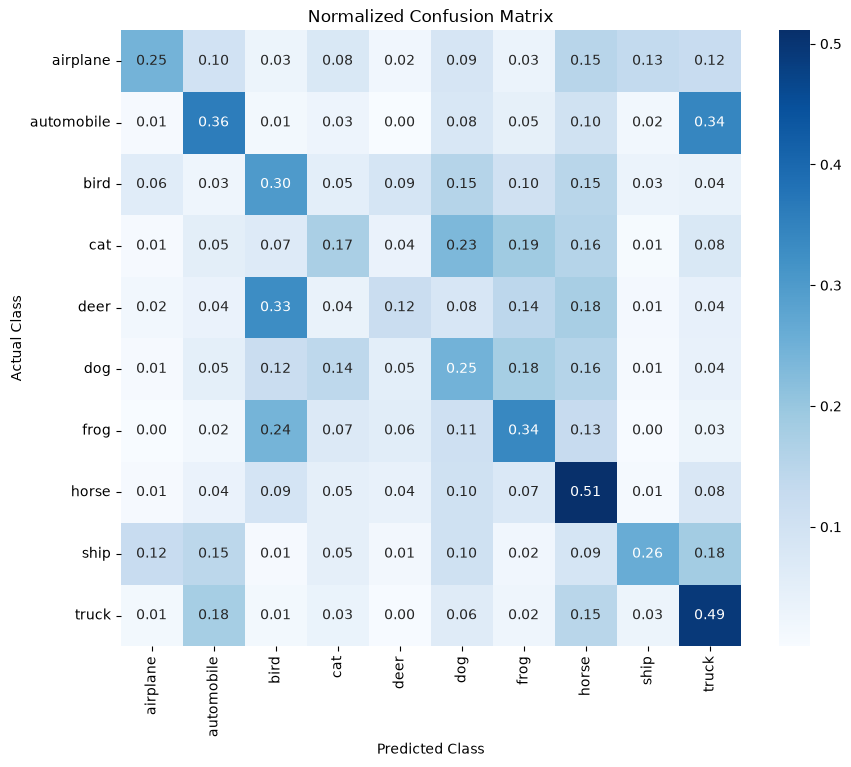

In [74]:
cm = confusion_matrix(
    y_true,
    y_pred,
    normalize="true"
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Normalized Confusion Matrix")
plt.show()

In [75]:
cm_counts = confusion_matrix(y_true, y_pred)
np.fill_diagonal(cm_counts, 0)

pairs = []

for i in range(10):
    for j in range(10):
        if i != j:
            pairs.append((
                cm_counts[i, j],
                class_names[i],
                class_names[j]
            ))

pairs.sort(reverse=True)

for count, actual, predicted in pairs[:5]:
    print(f"Actual: {actual} -> Predicted: {predicted}, Count: {count}")

Actual: automobile -> Predicted: truck, Count: 342
Actual: deer -> Predicted: bird, Count: 329
Actual: frog -> Predicted: bird, Count: 244
Actual: cat -> Predicted: dog, Count: 234
Actual: cat -> Predicted: frog, Count: 189


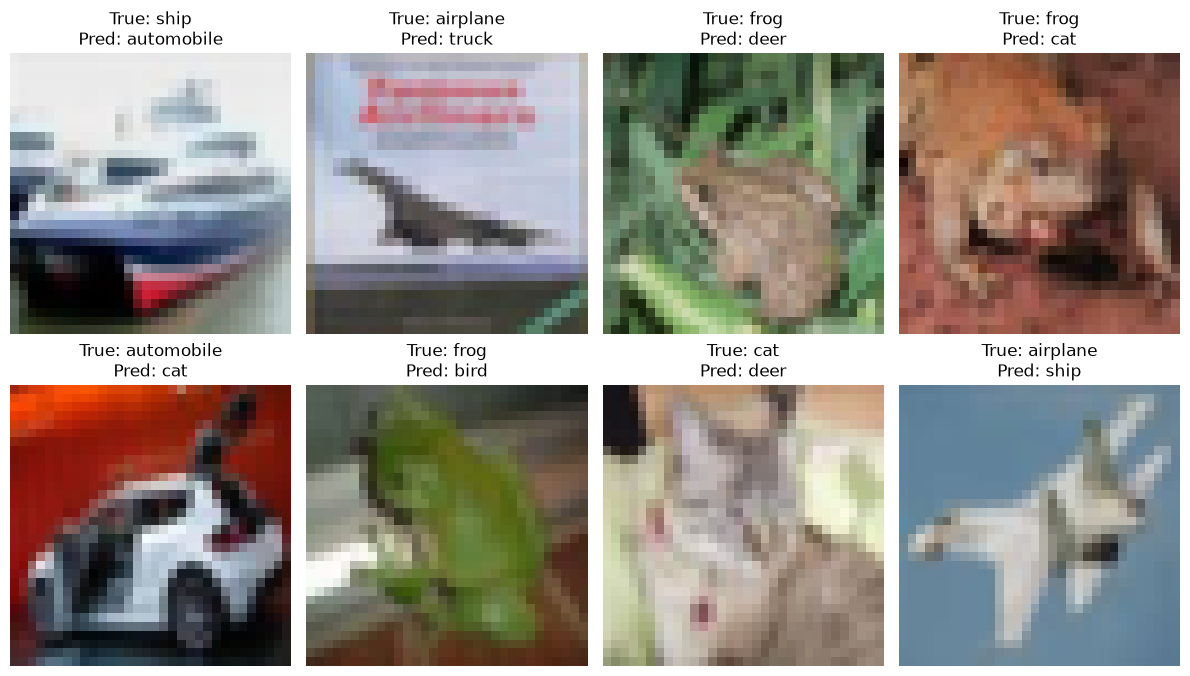

In [76]:
wrong_indices = np.where(y_pred != y_true)[0]

if len(wrong_indices) >= 8:
    plt.figure(figsize=(12, 7))

    for k, idx in enumerate(wrong_indices[:8]):
        plt.subplot(2, 4, k + 1)

        plt.imshow(
            np.clip(x_clean[idx], 0, 255).astype("uint8")
        )

        plt.title(
            f"True: {class_names[y_true[idx]]}\n"
            f"Pred: {class_names[y_pred[idx]]}"
        )

        plt.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("Fewer than 8 misclassified images found.")

In [77]:
x_hidden = tf.image.rgb_to_grayscale(
    tf.cast(x_clean, tf.float32)
)

x_hidden = tf.image.grayscale_to_rgb(x_hidden)

x_hidden = tf.cast(x_hidden, x_clean.dtype)

print("Hidden images shape:", x_hidden.shape)
print("Clean images shape:", x_clean.shape)

Hidden images shape: (10000, 32, 32, 3)
Clean images shape: (10000, 32, 32, 3)


In [78]:
print("Clean test shape:", x_clean.shape)
print("Clean labels shape:", y_clean.shape)

Clean test shape: (10000, 32, 32, 3)
Clean labels shape: (10000,)


In [79]:
hidden_loss, hidden_acc = model_final.evaluate(
    x_hidden,
    y_clean,
    verbose=1
)

print(
    "Hidden Corruption Accuracy:",
    round(hidden_acc * 100, 2),
    "%"
)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.1753 - loss: 2.2621
Hidden Corruption Accuracy: 17.53 %


The class accuracy table shows how well the model predicts each class. The confusion matrix shows which classes the model confuses most. We check at least 8 wrong images to find the reasons for the mistakes, such as similar shapes or unclear images. Finally, we test the model on hidden corruption to see if it can handle new changes in images.